<a href="https://colab.research.google.com/github/halynazhabchyk/nlp_labs/blob/main/NLP_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ПРАКТИЧНА РОБОТА 1: КЛАСИФІКАЦІЯ НОВИН НА ОСНОВІ
ЛОГІСТИЧНОЇ РЕГРЕСІЇ PYTORCH

Мета роботи: Ознайомитись із основами роботи з PyTorch для створення
моделей машинного навчання. Реалізувати модель логістичної регресії для
класифікації новинних текстів на основі датасету "20 Newsgroups".

1. Зібрати модель та провести навчання на даних

Першим етапом є імпорт бібліотек

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

Також додаємо вибір процесору(графічнний або центральний). Оскільки колаб має обмеження в часі на використання графічного процесору, будемо використовувати центральний

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

Завантажити датасет "20 Newsgroups", який
складається з текстів, що належать до 20 різних категорій. Він включає
навчальну та тестову вибірки.

In [ ]:
# import dataset module from sklearn.datasets
from sklearn.datasets import fetch_20newsgroups

In [ ]:
# import train data
newsgroups_train = fetch_20newsgroups(subset='train', remove=('headers',
'footers', 'quotes'))
# import test data
newsgroups_test = fetch_20newsgroups(subset='test', remove=('headers',
'footers', 'quotes'))

In [ ]:
# description of the test and training sample
print(f"Number of texts in the training sample:{len(newsgroups_train.data)}")
print(f"Number of texts in the testing sample: {len(newsgroups_test.data)}")
print(f"Number of classes: {len(newsgroups_train.target_names)}")
# Example text
print("\nExample of text from the training sample:")
print(newsgroups_train.data[1][:200]) # first 200 sumbols
print(f"\nText class:{newsgroups_train.target[0]}({newsgroups_train.target_names[newsgroups_train.target[0]]})")

Number of texts in the training sample:11314
Number of texts in the testing sample: 7532
Number of classes: 20

Example of text from the training sample:
A fair number of brave souls who upgraded their SI clock oscillator have
shared their experiences for this poll. Please send a brief message detailing
your experiences with the procedure. Top speed at

Text class:7(rec.autos)


Наступний крок - токенізація - це процес розбиття тексту на
базові лексичні елементи, токени. Токенами можуть бути слова, цифри або
спеціальні символи. Наприклад, у тексті "Привіт, як справи?" токенами
будуть: ["Привіт", "як", "справи"].

In [ ]:
import re

In [ ]:
# Text tokenization function
def tokenize_text_simple(text, min_token_length=4):
  tokens = re.findall(r'\b[a-zA-Z0-9]{4,}\b', text.lower())
  return [token for token in tokens if len(token)>= min_token_length]

In [ ]:
# Hull tokenization function
def tokenize_corpus(corpus):
    return [tokenize_text_simple(text) for text in corpus]


In [ ]:
tokenized_train = tokenize_corpus(newsgroups_train.data)
tokenized_test = tokenize_corpus(newsgroups_test.data)
# Example of tokenizing the first text
print("\nExample of tokenizing the first text:")
print(f"Original: {newsgroups_train.data[1][:200]}")
print(f"Tokens: {tokenized_train[1][:20]}") # Output the first 20 tokens
print(f"Original: {newsgroups_test.data[0][:201]}")
print(f"Tokens: {tokenized_test[1][:20]}") # Output the first 20 tokens


Example of tokenizing the first text:
Original: A fair number of brave souls who upgraded their SI clock oscillator have
shared their experiences for this poll. Please send a brief message detailing
your experiences with the procedure. Top speed at
Tokens: ['fair', 'number', 'brave', 'souls', 'upgraded', 'their', 'clock', 'oscillator', 'have', 'shared', 'their', 'experiences', 'this', 'poll', 'please', 'send', 'brief', 'message', 'detailing', 'your']
Original: I am a little confused on all of the models of the 88-89 bonnevilles.
I have heard of the LE SE LSE SSE SSEI. Could someone tell me the
differences are far as features or performance. I am also curious
Tokens: ['familiar', 'with', 'format', 'these', 'face', 'thingies', 'after', 'seeing', 'them', 'some', 'folks', 'headers', 'them', 'maybe', 'make', 'view', 'linux', 'which', 'displays', 'uncompressed']


Далі реалізуємо функцію побудови словника Словник у задачах обробки текстів – це структура
даних, яка відображає кожне слово (токен) у його числовий індекс. Оскільки
комп’ютери не можуть працювати з текстами безпосередньо, всі слова
повинні бути представлені у вигляді чисел. Наприклад:
{"машина": 1, "працює": 2, "добре": 3, "<UNK>": 0}

In [ ]:
from collections import defaultdict

def build_vocabulary(tokenized_text,
                     min_freq=5,
                     max_doc_freq=0.8,
                     max_vocab_size=20000):

  token_counts = defaultdict(int)
  num_docs = len(tokenized_text)
  for tokens in tokenized_text:
    unique_tokens = set(tokens)
    for token in unique_tokens:
      token_counts[token]+=1

  filtered_tokens ={
      token: count
      for token, count in token_counts.items()
      if count >= min_freq and count/num_docs <= max_doc_freq
  }

  sorted_tokens = sorted(filtered_tokens.items(), key=lambda x: x[1], reverse=True)

  sorted_tokens = sorted_tokens[:max_vocab_size]

  word_to_id = {"<UNK>": 0}
  for idx, (token, _) in enumerate(sorted_tokens, start=1):
        word_to_id[token] = idx

  word_to_frequency = [filtered_tokens.get(token, 0) / num_docs for token in word_to_id]
  return word_to_id, word_to_frequency

In [ ]:
word_to_id_train, word_to_frequency_train = build_vocabulary(tokenized_train,
                                                 min_freq=5,
                                                 max_doc_freq=0.8,
                                                 max_vocab_size=20000)
print("Training set token dictionary (word_to_id):", word_to_id_train)
print("Training set token frequencies (word_to_frequency):", word_to_frequency_train)


Training set token dictionary (word_to_id): {'<UNK>': 0, 'that': 1, 'this': 2, 'have': 3, 'with': 4, 'from': 5, 'they': 6, 'there': 7, 'would': 8, 'what': 9, 'about': 10, 'will': 11, 'some': 12, 'like': 13, 'just': 14, 'your': 15, 'which': 16, 'know': 17, 'more': 18, 'when': 19, 'only': 20, 'other': 21, 'than': 22, 'also': 23, 'think': 24, 'them': 25, 'been': 26, 'does': 27, 'people': 28, 'their': 29, 'time': 30, 'were': 31, 'then': 32, 'could': 33, 'well': 34, 'good': 35, 'these': 36, 'should': 37, 'even': 38, 'very': 39, 'much': 40, 'because': 41, 'make': 42, 'anyone': 43, 'here': 44, 'into': 45, 'first': 46, 'most': 47, 'where': 48, 'many': 49, 'such': 50, 'same': 51, 'want': 52, 'used': 53, 'those': 54, 'thanks': 55, 'need': 56, 'please': 57, 'after': 58, 'being': 59, 'right': 60, 'over': 61, 'something': 62, 'since': 63, 'really': 64, 'work': 65, 'problem': 66, 'still': 67, 'back': 68, 'before': 69, 'find': 70, 'using': 71, 'system': 72, 'take': 73, 'last': 74, 'years': 75, 'point

Для наочності додамо побудову графіка розподілу за законом Ципфа.
Якщо взяти текст на будь-якій природній мові,
то найбільш уживане слово (ранг 𝑟 = 1) зустрічається найчастіше, друге за
частотою слово – приблизно вдвічі рідше (𝑟 = 2), третє – у три рази рідше (𝑟
= 3) і так далі.


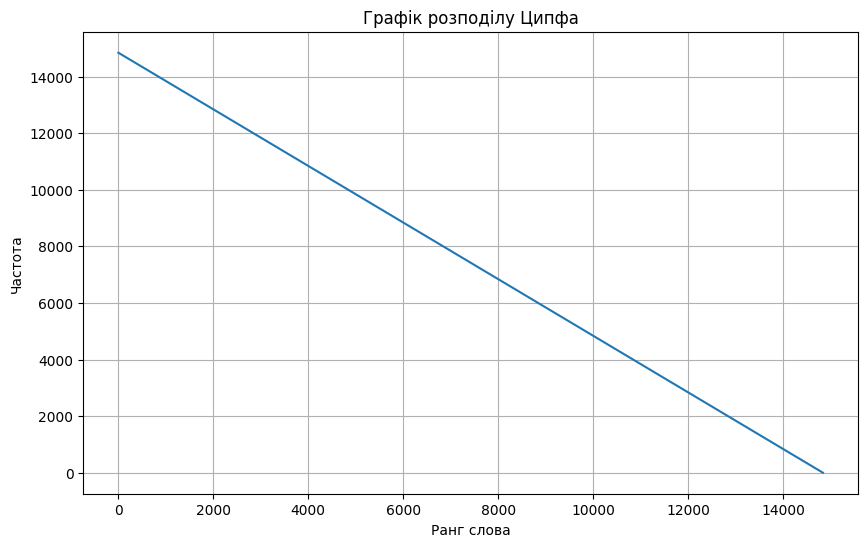

In [ ]:
frequencies_train = [freq for _, freq in sorted(word_to_id_train.items(), key=lambda x: x[1])]
plt.figure(figsize=(10, 6))
plt.plot(range(len(frequencies_train)), sorted(frequencies_train, reverse=True))
plt.xlabel("Ранг слова")
plt.ylabel("Частота")
plt.title("Графік розподілу Ципфа")
plt.grid()
plt.show()

Бачимо, що  залежність частоти
від рангу виглядатиме як пряма лінія.Тобто, частоти токенів у корпусі слідують
закону Ципфа

Далі розширимо наш аналіз, побудуємо:
1. Розподіл частот токенів (графік Ципфа).
2. Гістограму частот токенів.
20
3. Аналіз кількості токенів, які зустрічаються в різному відсотку документів.

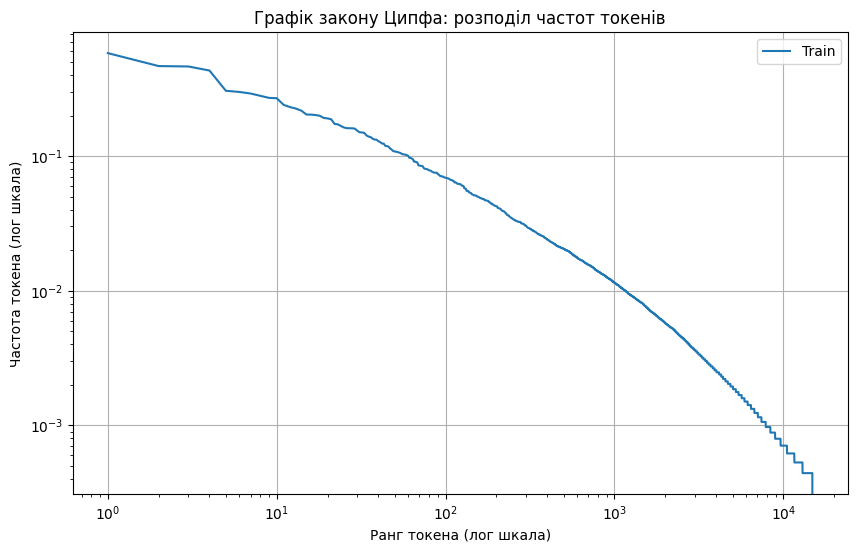

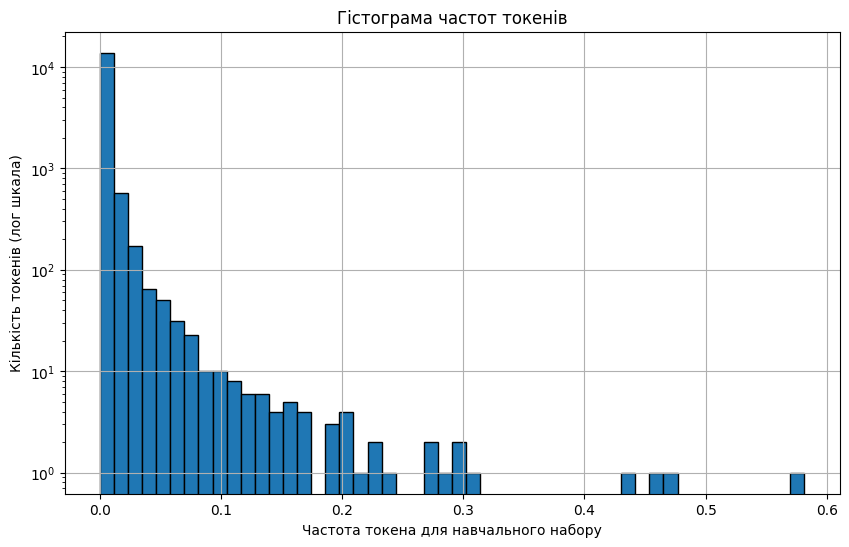

Токенів, які зустрічаються у понад 50% документів: 1
Токенів, які зустрічаються у понад 10% документів: 60
Токенів, які зустрічаються у понад 5% документів: 155
Токенів, які зустрічаються у понад 1% документів: 1153


In [ ]:
token_frequencies_train = np.array(list(word_to_frequency_train))
# 1. Zipf distribution chart
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(token_frequencies_train) + 1), sorted(token_frequencies_train,reverse=True), label='Train')
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Ранг токена (лог шкала)")
plt.ylabel("Частота токена (лог шкала)")
plt.title("Графік закону Ципфа: розподіл частот токенів")
plt.legend()
plt.grid()
plt.show()
# 2. Token frequency histogram
plt.figure(figsize=(10, 6))
plt.hist(token_frequencies_train, bins=50, log=True, edgecolor="black")
plt.xlabel("Частота токена для навчального набору")
plt.ylabel("Кількість токенів (лог шкала)")
plt.title("Гістограма частот токенів")
plt.grid()
plt.show()
# 3. Number of tokens by coverage criteria
thresholds = [0.5, 0.1, 0.05, 0.01]
token_counts = [(token_frequencies_train > threshold).sum() for threshold in thresholds]

for threshold, count in zip(thresholds, token_counts):
 print(f"Токенів, які зустрічаються у понад {threshold * 100:.0f}% документів: {count}")



1. Графік розподілу Ципфа: бачимо, що частоти токенів
підпорядковуються закону Ципфа. Найчастотніші токени (на початку
графіка) мають значно більшу частоту, ніж рідкісні токени (на кінці
графіка).
2. Гістограма частот токенів: підтверджує, що більшість токенів мають
дуже низьку частоту.
3. Кількість токенів за критеріями: токенів, які зустрічаються у понад
50% документів, дуже мало. Токенів, які
зустрічаються хоча 60 у 10% документів, більше, але їх усе одно менше
ніж кілька сотень. Найбільша кількість токенів зустрічається у 1%-5% документів, що відповідає "хвосту" закону Ципфа.

Наступний крок: побудова графіків розподілу по класах для тестової та навчальної вибірки

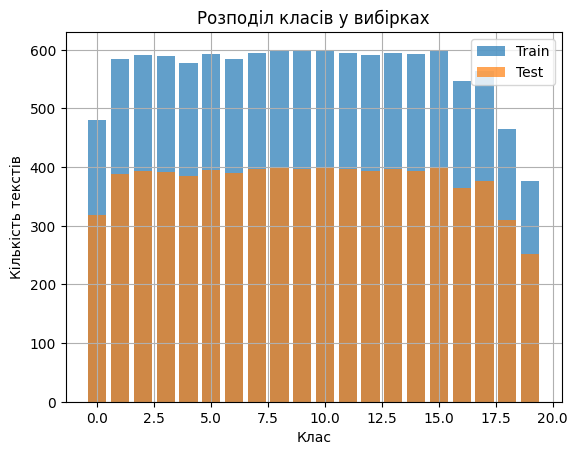

In [ ]:
labels_train = newsgroups_train.target
labels_test = newsgroups_test.target

unique, counts = np.unique(labels_train, return_counts=True)
plt.bar(unique, counts, alpha=0.7, label='Train')

unique, counts = np.unique(labels_test, return_counts=True)
plt.bar(unique, counts, alpha=0.7, label='Test')
plt.title("Розподіл класів у вибірках")
plt.xlabel("Клас")
plt.ylabel("Кількість текстів")
plt.legend()
plt.grid()
plt.show()

Усі 20 класів представлені приблизно однаковою кількістю текстів, що є важливим для коректної оцінки якості моделі. Рівномірний розподіл забезпечує відсутність перекосу в бік окремих класів, тому показник точності (accuracy) можна використовувати як основну метрику оцінювання. У разі нерівномірного розподілу виникла б потреба застосовувати метрики, стійкі до дисбалансу класів, зокрема F1-score або AUC-ROC.


Далі потрібно реалізувати векторизацію, побудову матриці ознак (feature matrix).
Векторизація – це процес перетворення сирих даних (наприклад,
текстів, зображень або сигналів) у числовий формат, зручний для аналізу та
обробки алгоритмами машинного навчання. У контексті текстів та інших
структурованих даних векторизація є першим кроком для створення
матриці ознак (feature matrix).

Спочатку ми напишемо методи реалізації векторизації тексту та побудови розрідженої матриці вручну. Та порівняємо результати точності цих моделей із іншими вбудованими методами векторизації та побудови словника.

In [ ]:
from scipy.sparse import csr_matrix


def vectorize_texts(
    tokenized_texts,
    word_to_id,
    word_to_frequency=None,
    mode='TF-IDF',
    scale=True
):

    # Chech the mode
    assert mode in ['bin', 'TF', 'IDF', 'TF-IDF'], "Unsupported mode"

    num_texts = len(tokenized_texts)
    vocab_size = len(word_to_id)

    # Data for sparse-matrix
    data, rows, cols = [], [], []


    for i, tokens in enumerate(tokenized_texts):
        for token in tokens:
            if token in word_to_id:
                token_id = word_to_id[token]
                data.append(1)
                rows.append(i)
                cols.append(token_id)

    # Frequency matrix
    freq_matrix = csr_matrix(
        (data, (rows, cols)),
        shape=(num_texts, vocab_size),
        dtype=float
    )

    # === BIN ===
    if mode == 'bin':
        freq_matrix.data = np.ones_like(freq_matrix.data)

    # === TF ===
    elif mode == 'TF':
        row_sums = np.array(freq_matrix.sum(axis=1)).flatten()
        row_sums[row_sums == 0] = 1
        freq_matrix = freq_matrix.multiply(1 / row_sums[:, None])

    # === IDF ===
    elif mode == 'IDF':
        doc_freq = np.array((freq_matrix > 0).sum(axis=0)).flatten()
        idf = np.log((num_texts + 1) / (doc_freq + 1)) + 1
        freq_matrix = freq_matrix.multiply(idf)

    # === TF-IDF ===
    elif mode == 'TF-IDF':
        # TF
        row_sums = np.array(freq_matrix.sum(axis=1)).flatten()
        row_sums[row_sums == 0] = 1
        tf = freq_matrix.multiply(1 / row_sums[:, None])

        # IDF
        doc_freq = np.array((freq_matrix > 0).sum(axis=0)).flatten()
        idf = np.log((num_texts + 1) / (doc_freq + 1)) + 1

        freq_matrix = tf.multiply(idf)

    # === Scaling ===
    if scale:
        max_val = freq_matrix.max()
        if max_val > 0:
            freq_matrix = freq_matrix.multiply(1 / max_val)

    # === Matrix density ===
    total_elements = num_texts * vocab_size
    non_zero_elements = freq_matrix.count_nonzero()
    density = (non_zero_elements / total_elements) * 100

    print(f"Matrix density: {density:.2f}%")

    return freq_matrix.tocsr()


In [ ]:
feature_matrix_train = vectorize_texts(tokenized_texts=tokenized_train,
                                 word_to_id = word_to_id_train,
                                 word_to_frequency=word_to_frequency_train, mode='TF-IDF')

feature_matrix_test = vectorize_texts(tokenized_texts=tokenized_test,
                                 word_to_id = word_to_id_train,
                                 word_to_frequency=word_to_frequency_train, mode='TF-IDF')
print("Матриця ознак (TF-IDF) тренувального набру:")
print(feature_matrix_train.toarray())
print("Матриця ознак (TF-IDF) тестового набору:")
print(feature_matrix_test.toarray())

Matrix density: 0.42%
Matrix density: 0.40%
Матриця ознак (TF-IDF) тренувального набру:
[[0.         0.         0.01828021 ... 0.         0.         0.        ]
 [0.         0.         0.00737622 ... 0.         0.         0.        ]
 [0.         0.00362818 0.00414913 ... 0.         0.         0.        ]
 ...
 [0.         0.00399626 0.00457005 ... 0.         0.         0.        ]
 [0.         0.01838278 0.01401483 ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]
Матриця ознак (TF-IDF) тестового набору:
[[0.         0.0042513  0.00496616 ... 0.         0.         0.        ]
 [0.         0.00415008 0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.00544698 0.00636289 ... 0.         0.         0.        ]
 [0.         0.         0.01357416 ... 0.         0.         0.        ]
 [0.         0.01376079 0.03214932 ... 0.         0.     

Матриця ознак є числовим представленням текстових даних, яке використовується як вхід для алгоритмів машинного навчання. У межах підходу «мішка слів» кожен текст перетворюється на вектор, компоненти якого відображають певні характеристики слів у цьому тексті.

У результаті формується матриця ознак, де рядки відповідають окремим текстам, а стовпці — словам зі сформованого словника. Значення елементів матриці визначаються обраним методом зважування (наприклад, частотою слова або TF-IDF).

Оскільки така матриця зазвичай містить велику кількість нульових значень, її доцільно зберігати у розрідженому форматі. Використання структури csr_matrix з бібліотеки scipy.sparse дозволяє ефективно використовувати пам’ять, оскільки зберігаються лише ненульові елементи.

Побудуємо деякі графіки для аналізу.
Розподіл значень у матрицях ознак для тренувального набору.

Matrix density: 0.42%
Matrix density: 0.42%
Matrix density: 0.42%
Matrix density: 0.42%


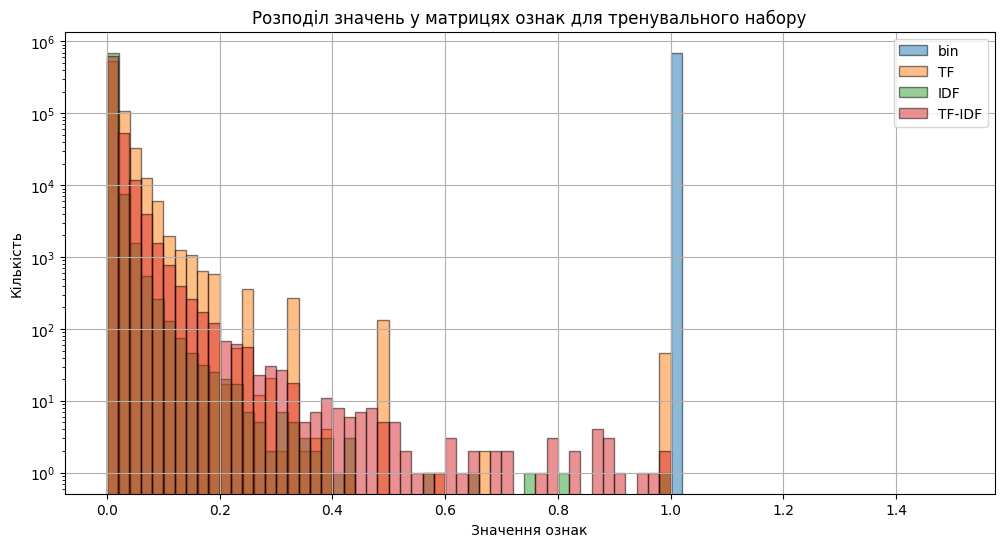

In [ ]:
modes = ['bin', 'TF', 'IDF', 'TF-IDF']

feature_matrices_train = {
    mode: vectorize_texts(
        tokenized_texts=tokenized_train,
        word_to_id=word_to_id_train,
        mode=mode
    )
    for mode in modes
}

plt.figure(figsize=(12, 6))

for mode, matrix in feature_matrices_train.items():
    plt.hist(
        matrix.data,
        bins=50,
        alpha=0.5,
        label=mode,
        log=True,
        edgecolor="black"
    )

plt.xlabel("Значення ознак")
plt.ylabel("Кількість")
plt.title("Розподіл значень у матрицях ознак для тренувального набору")
plt.legend()
plt.grid(True)
plt.show()


Matrix density: 0.40%
Matrix density: 0.40%
Matrix density: 0.40%
Matrix density: 0.40%


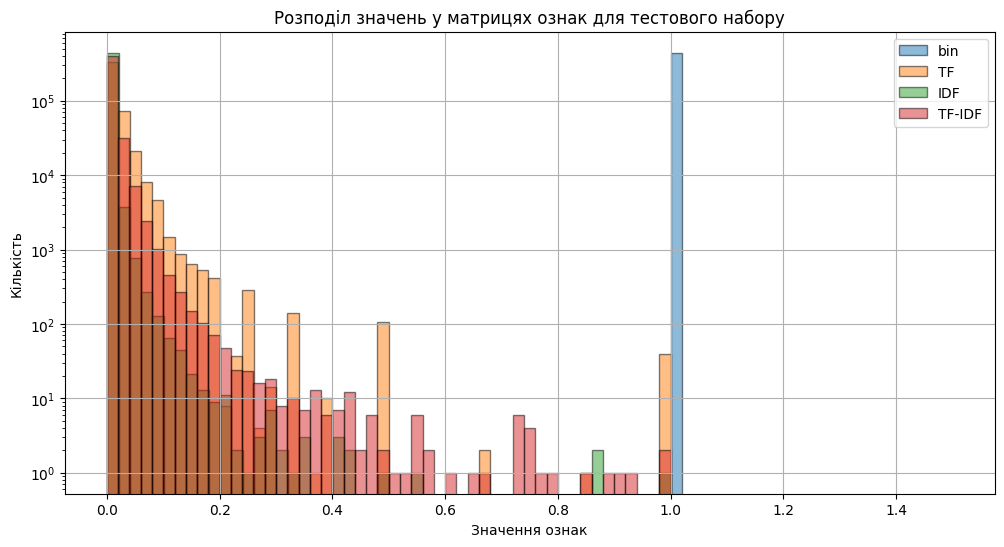

In [ ]:
feature_matrices_test = {
    mode: vectorize_texts(
        tokenized_texts=tokenized_test,
        word_to_id=word_to_id_train,
        mode=mode
    )
    for mode in modes
}

plt.figure(figsize=(12, 6))

for mode, matrix in feature_matrices_test.items():
    plt.hist(
        matrix.data,
        bins=50,
        alpha=0.5,
        label=mode,
        log=True,
        edgecolor="black"
    )

plt.xlabel("Значення ознак")
plt.ylabel("Кількість")
plt.title("Розподіл значень у матрицях ознак для тестового набору")
plt.legend()
plt.grid(True)
plt.show()


Можна побачити, що найменший розмах значень для методу BIN оскільки він не враховує частоти слів. Найбільш широкий розподіл спостерігається у режимі поєднання TF і IDF, оскільки значення відображають частотність слова в тексті та його важливість
у корпусі. Тому він найкраще підходить для тематичної класифікації.

Тепер приведемо спосіб перставлення даних у формат, який є
найбільш ефективним для використання коли маємо справу із PyTorch.
PyTorch Dataset

Для навчання моделей у PyTorch ми використовуємо DataLoader, який
автоматично формує батчі, забезпечує багатопоточність і перемішування
даних.

Приклад реалізації Dataset для розріджених матриць

In [ ]:
from torch.utils.data import Dataset
class SparseFeatureDataset(Dataset):
  def __init__(self,features,labels):
    self.features=features
    self.labels=labels
    super().__init__()
  def __len__(self):
    return self.features.shape[0]
  def __getitem__(self, idx):
    feature = torch.tensor(
        self.features[idx].toarray().squeeze(),
        dtype=torch.float32
    )
    label = torch.tensor(self.labels[idx], dtype=torch.long)
    return feature, label




In [ ]:
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix

def prepare_data(features, labels, batch_size=32, shuffle=True):
    dataset = SparseFeatureDataset(features, labels)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)
    return dataset, dataloader


train_data, train_dataloader = prepare_data(
    feature_matrix_train,
    labels_train,
    shuffle=True
)

test_data, test_dataloader = prepare_data(
    feature_matrix_test,
    labels_test,
    shuffle=False
)

Перевіримо розміри даталодерів

In [ ]:
features, labels = next(iter(train_dataloader))
print(features.shape)
print(labels.shape)


torch.Size([32, 14843])
torch.Size([32])


Реалізуємо процес підготовки даних у вигляді даталодерів для кожного режиму

In [ ]:
modes = ['bin', 'TF', 'IDF', 'TF-IDF']
datasets = {}

for mode in modes:
    print(f"\n=== Mode: {mode} ===")

    # Vectorize
    X_train = vectorize_texts(
        tokenized_train,
        word_to_id_train,
        mode=mode
    )

    X_test = vectorize_texts(
        tokenized_test,
        word_to_id_train,
        mode=mode
    )

    #  Dataset + DataLoader
    train_data, train_loader = prepare_data(
        X_train,
        labels_train,
        batch_size=32,
        shuffle=True
    )

    test_data, test_loader = prepare_data(
        X_test,
        labels_test,
        batch_size=32,
        shuffle=False
    )

    # Saving
    datasets[mode] = {
        'train_loader': train_loader,
        'test_loader': test_loader
    }

print(datasets)



=== Mode: bin ===
Matrix density: 0.42%
Matrix density: 0.40%

=== Mode: TF ===
Matrix density: 0.42%
Matrix density: 0.40%

=== Mode: IDF ===
Matrix density: 0.42%
Matrix density: 0.40%

=== Mode: TF-IDF ===
Matrix density: 0.42%
Matrix density: 0.40%
{'bin': {'train_loader': <torch.utils.data.dataloader.DataLoader object at 0x7ca2c4622960>, 'test_loader': <torch.utils.data.dataloader.DataLoader object at 0x7ca2b9f028a0>}, 'TF': {'train_loader': <torch.utils.data.dataloader.DataLoader object at 0x7ca2c4621be0>, 'test_loader': <torch.utils.data.dataloader.DataLoader object at 0x7ca2c4622ea0>}, 'IDF': {'train_loader': <torch.utils.data.dataloader.DataLoader object at 0x7ca2c44fccb0>, 'test_loader': <torch.utils.data.dataloader.DataLoader object at 0x7ca2b92be9f0>}, 'TF-IDF': {'train_loader': <torch.utils.data.dataloader.DataLoader object at 0x7ca31e46bda0>, 'test_loader': <torch.utils.data.dataloader.DataLoader object at 0x7ca2c033c5f0>}}


Далі ми реалзуємо логічтичну регресію

In [ ]:
class LogisticRegressionModel(nn.Module):
 def __init__(self, input_size, num_classes):
  super(LogisticRegressionModel, self).__init__()
  self.linear = nn.Linear(input_size, num_classes)

 def forward(self, x):
  return self.linear(x)

Далі створимо одну модель для одного режиму для перевірки

In [ ]:
# Check dimensions
input_dim = feature_matrix_train.shape[1]
output_dim = len(set(newsgroups_train.target))


# Initialize the model
model = LogisticRegressionModel(input_dim, output_dim)
# Loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


In [ ]:
input_dim, output_dim

(14843, 20)

In [ ]:
input_dim_t = feature_matrix_test.shape[1]
output_dim_t= len(set(newsgroups_test.target))
input_dim_t, output_dim_t

(14843, 20)

Для метрики  точності встановлюємо Torchmetrics

In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 31.2 MB/s eta 0:00:00


In [ ]:
from torchmetrics import Accuracy
accuracy = Accuracy(task="multiclass", num_classes=len(newsgroups_train.target_names)).to(device)
def accuracy_fn():
  return accuracy

In [ ]:
len(newsgroups_train.target_names)

20

Реалізація функції навчального кроку

In [ ]:
def train_step(model, dataloader, optimizer, loss_fn, accuracy_fn, device ):
  model.train()
  train_loss = 0
  acc = accuracy_fn()
  acc.reset()
  for batch, (X,y) in enumerate(dataloader):
    X, y = X.to(device), y.to(device)

    train_pred = model(X)
    loss = loss_fn(train_pred, y)
    train_loss+= loss.item()
    acc.update(train_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # y_pred_class = torch.argmax(torch.softmax(train_pred, dim =1), dim =1)

  train_loss = train_loss/ len(dataloader)
  train_accuracy = acc.compute().item()
  return train_loss, train_accuracy



Реалізація функції кроку тестування

In [ ]:
def test_step (model, dataloader, loss_fn, accuracy_fn, device):
  model.eval()
  test_loss = 0
  acc = accuracy_fn()
  acc.reset()
  with torch.inference_mode():
    for batch, (X,y) in enumerate(dataloader):
      X, y = X.to(device), y.to(device)
      test_pred = model(X)

      loss = loss_fn(test_pred, y)
      test_loss+= loss.item()
      acc.update(test_pred, y)

    test_loss = test_loss / len(dataloader)
    test_acc = acc.compute().item()
    return test_loss, test_acc


Загальна функція для тренування та тестування моделі

In [ ]:
from tqdm.auto import tqdm
def train(model, train_dataloader,
          test_dataloader, optimizer,
          loss_fn, accuracy_fn,
          epochs, device):
  results ={"train_loss": [],
            "train_acc": [],
            "test_loss": [],
            "test_acc": []
            }

  for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train_step(model=model,
                                       dataloader=train_dataloader,
                                       optimizer=optimizer,
                                       loss_fn = loss_fn,
                                       accuracy_fn = accuracy_fn,
                                       device=device)
    test_loss, test_acc = test_step(model=model,
                                    dataloader=test_dataloader,
                                    loss_fn=loss_fn,
                                    accuracy_fn=accuracy_fn,
                                    device=device)
    print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

    # 5. Update results dictionary
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

    # 6. Return the filled results at the end of the epochs
  return results


In [ ]:
torch.manual_seed(seed=42)
results = train(model=model,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                accuracy_fn=accuracy_fn,
                epochs=10,
                device=device)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 2.9832 | train_acc: 0.2409 | test_loss: 2.9732 | test_acc: 0.4967
Epoch: 2 | train_loss: 2.9529 | train_acc: 0.6031 | test_loss: 2.9533 | test_acc: 0.5068
Epoch: 3 | train_loss: 2.9244 | train_acc: 0.6839 | test_loss: 2.9342 | test_acc: 0.5255
Epoch: 4 | train_loss: 2.8965 | train_acc: 0.7088 | test_loss: 2.9156 | test_acc: 0.5571
Epoch: 5 | train_loss: 2.8689 | train_acc: 0.7393 | test_loss: 2.8973 | test_acc: 0.5628
Epoch: 6 | train_loss: 2.8415 | train_acc: 0.7551 | test_loss: 2.8791 | test_acc: 0.5741
Epoch: 7 | train_loss: 2.8144 | train_acc: 0.7706 | test_loss: 2.8611 | test_acc: 0.5743
Epoch: 8 | train_loss: 2.7874 | train_acc: 0.7799 | test_loss: 2.8433 | test_acc: 0.5786
Epoch: 9 | train_loss: 2.7604 | train_acc: 0.7850 | test_loss: 2.8256 | test_acc: 0.5852
Epoch: 10 | train_loss: 2.7338 | train_acc: 0.7949 | test_loss: 2.8079 | test_acc: 0.5890


Бачимо, що модель тренується та працює, тому зробимо цикл для різних методів векторизації вручну

In [ ]:
torch.manual_seed(seed=42)
all_results = {}
for mode in modes:
    print(f"\n=== Mode: {mode} ===")

    train_loader = datasets[mode]['train_loader']
    test_loader = datasets[mode]['test_loader']

    model = LogisticRegressionModel(input_dim, output_dim)
    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    metrics = train(
        model,
        train_loader,
        test_loader,
        optimizer,
        loss_fn,
        accuracy_fn,
        epochs=10,
        device=device)

    all_results[mode] = {
        "model": model,
        "metrics": metrics}


=== Mode: bin ===


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.5043 | train_acc: 0.6047 | test_loss: 1.4276 | test_acc: 0.6236
Epoch: 2 | train_loss: 0.5068 | train_acc: 0.8937 | test_loss: 1.3979 | test_acc: 0.6287
Epoch: 3 | train_loss: 0.3357 | train_acc: 0.9396 | test_loss: 1.4367 | test_acc: 0.6287
Epoch: 4 | train_loss: 0.2588 | train_acc: 0.9547 | test_loss: 1.4772 | test_acc: 0.6190
Epoch: 5 | train_loss: 0.2109 | train_acc: 0.9604 | test_loss: 1.5299 | test_acc: 0.6131
Epoch: 6 | train_loss: 0.1826 | train_acc: 0.9641 | test_loss: 1.5749 | test_acc: 0.6065
Epoch: 7 | train_loss: 0.1636 | train_acc: 0.9670 | test_loss: 1.6323 | test_acc: 0.6020
Epoch: 8 | train_loss: 0.1504 | train_acc: 0.9677 | test_loss: 1.6856 | test_acc: 0.5976
Epoch: 9 | train_loss: 0.1387 | train_acc: 0.9688 | test_loss: 1.7402 | test_acc: 0.5912
Epoch: 10 | train_loss: 0.1309 | train_acc: 0.9697 | test_loss: 1.7850 | test_acc: 0.5904

=== Mode: TF ===


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 2.8211 | train_acc: 0.3879 | test_loss: 2.6857 | test_acc: 0.5765
Epoch: 2 | train_loss: 2.4384 | train_acc: 0.7412 | test_loss: 2.4479 | test_acc: 0.5730
Epoch: 3 | train_loss: 2.1210 | train_acc: 0.8053 | test_loss: 2.2526 | test_acc: 0.6142
Epoch: 4 | train_loss: 1.8536 | train_acc: 0.8400 | test_loss: 2.0951 | test_acc: 0.6207
Epoch: 5 | train_loss: 1.6291 | train_acc: 0.8619 | test_loss: 1.9678 | test_acc: 0.6276
Epoch: 6 | train_loss: 1.4428 | train_acc: 0.8774 | test_loss: 1.8635 | test_acc: 0.6328
Epoch: 7 | train_loss: 1.2854 | train_acc: 0.8903 | test_loss: 1.7780 | test_acc: 0.6344
Epoch: 8 | train_loss: 1.1527 | train_acc: 0.8988 | test_loss: 1.7088 | test_acc: 0.6358
Epoch: 9 | train_loss: 1.0397 | train_acc: 0.9060 | test_loss: 1.6496 | test_acc: 0.6401
Epoch: 10 | train_loss: 0.9433 | train_acc: 0.9144 | test_loss: 1.6010 | test_acc: 0.6389

=== Mode: IDF ===


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 2.9308 | train_acc: 0.1689 | test_loss: 2.8972 | test_acc: 0.1602
Epoch: 2 | train_loss: 2.8132 | train_acc: 0.3914 | test_loss: 2.8264 | test_acc: 0.3733
Epoch: 3 | train_loss: 2.7186 | train_acc: 0.4809 | test_loss: 2.7670 | test_acc: 0.3562
Epoch: 4 | train_loss: 2.6344 | train_acc: 0.5753 | test_loss: 2.7130 | test_acc: 0.4193
Epoch: 5 | train_loss: 2.5570 | train_acc: 0.6043 | test_loss: 2.6640 | test_acc: 0.4312
Epoch: 6 | train_loss: 2.4856 | train_acc: 0.6335 | test_loss: 2.6180 | test_acc: 0.4946
Epoch: 7 | train_loss: 2.4185 | train_acc: 0.6594 | test_loss: 2.5755 | test_acc: 0.4965
Epoch: 8 | train_loss: 2.3560 | train_acc: 0.6882 | test_loss: 2.5350 | test_acc: 0.5166
Epoch: 9 | train_loss: 2.2961 | train_acc: 0.7129 | test_loss: 2.4966 | test_acc: 0.5196
Epoch: 10 | train_loss: 2.2394 | train_acc: 0.7314 | test_loss: 2.4596 | test_acc: 0.5333

=== Mode: TF-IDF ===


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 2.8839 | train_acc: 0.3817 | test_loss: 2.8045 | test_acc: 0.4425
Epoch: 2 | train_loss: 2.6198 | train_acc: 0.7285 | test_loss: 2.6398 | test_acc: 0.5522
Epoch: 3 | train_loss: 2.3795 | train_acc: 0.8076 | test_loss: 2.4903 | test_acc: 0.6142
Epoch: 4 | train_loss: 2.1594 | train_acc: 0.8481 | test_loss: 2.3567 | test_acc: 0.6267
Epoch: 5 | train_loss: 1.9604 | train_acc: 0.8735 | test_loss: 2.2381 | test_acc: 0.6371
Epoch: 6 | train_loss: 1.7821 | train_acc: 0.8867 | test_loss: 2.1335 | test_acc: 0.6346
Epoch: 7 | train_loss: 1.6233 | train_acc: 0.8981 | test_loss: 2.0398 | test_acc: 0.6471
Epoch: 8 | train_loss: 1.4817 | train_acc: 0.9075 | test_loss: 1.9582 | test_acc: 0.6483
Epoch: 9 | train_loss: 1.3557 | train_acc: 0.9122 | test_loss: 1.8857 | test_acc: 0.6467
Epoch: 10 | train_loss: 1.2440 | train_acc: 0.9157 | test_loss: 1.8227 | test_acc: 0.6531


Для досягнення кращих результатів можна збільшити кількість епох. Рівень lr=0.01 є оптимальним, тому що модель з рівномірною швидкістю збільшує свою точність і мінімізує втрати.

Побудуємо графіки точності та втрат

In [ ]:
from typing import Dict,List
def plot_loss_curves(results: Dict[str, List[float]]):
    """Plots training curves of a results dictionary.

    Args:
        results (dict): dictionary containing list of values, e.g.
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """

    # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();


=== Mode: bin ===

=== Mode: TF ===

=== Mode: IDF ===

=== Mode: TF-IDF ===


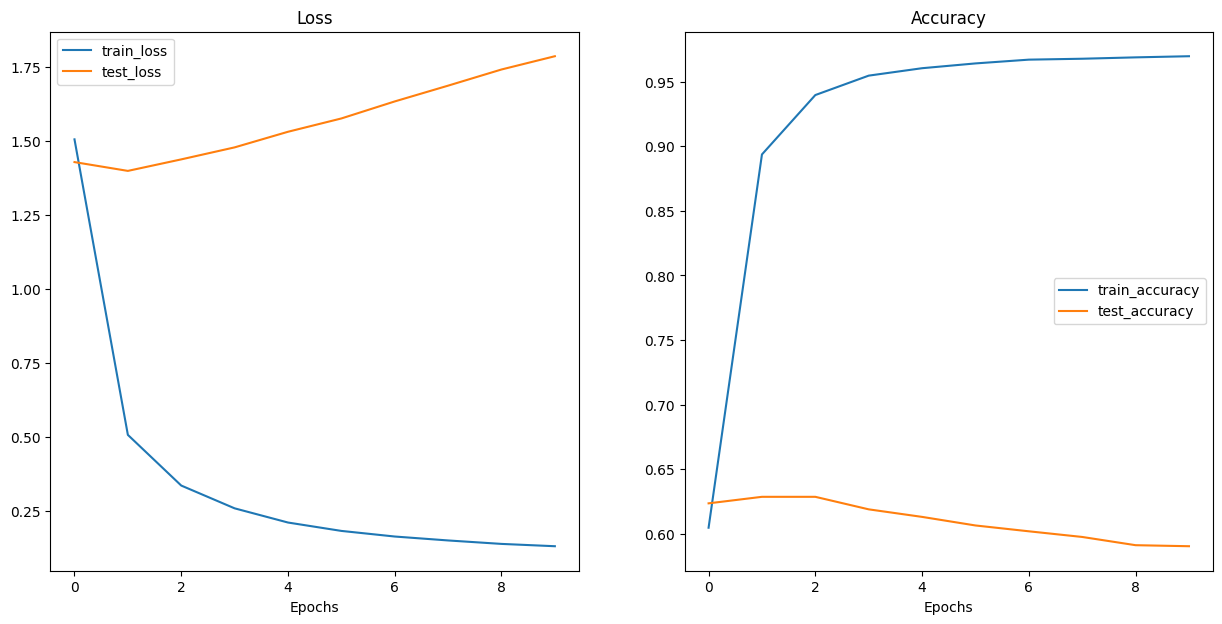

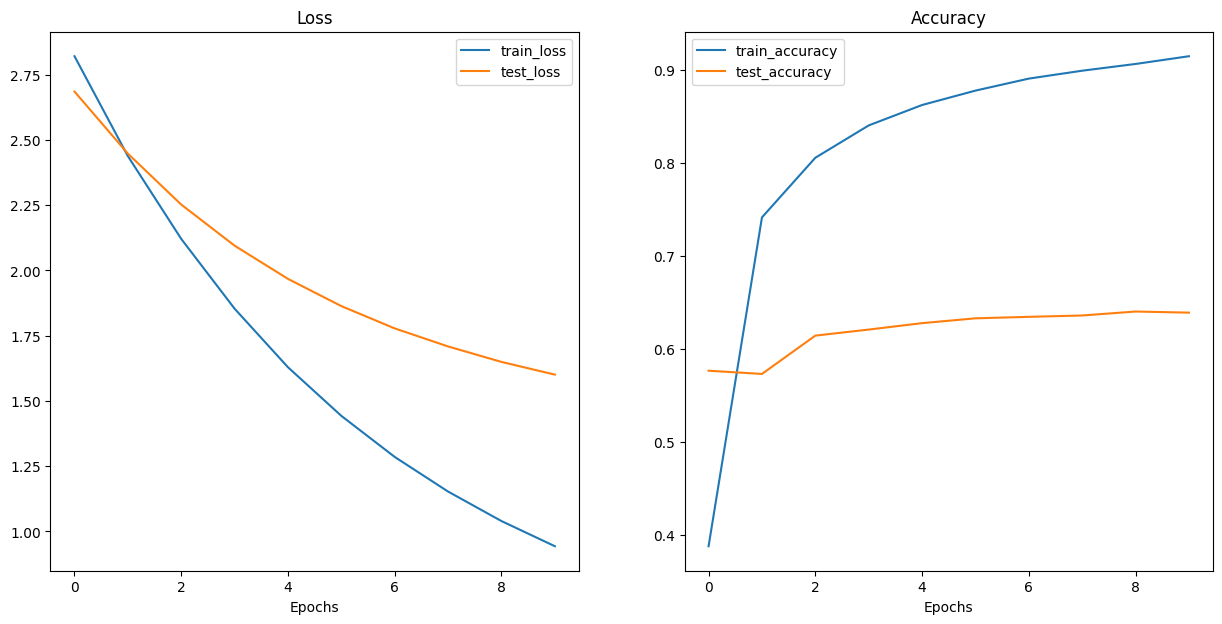

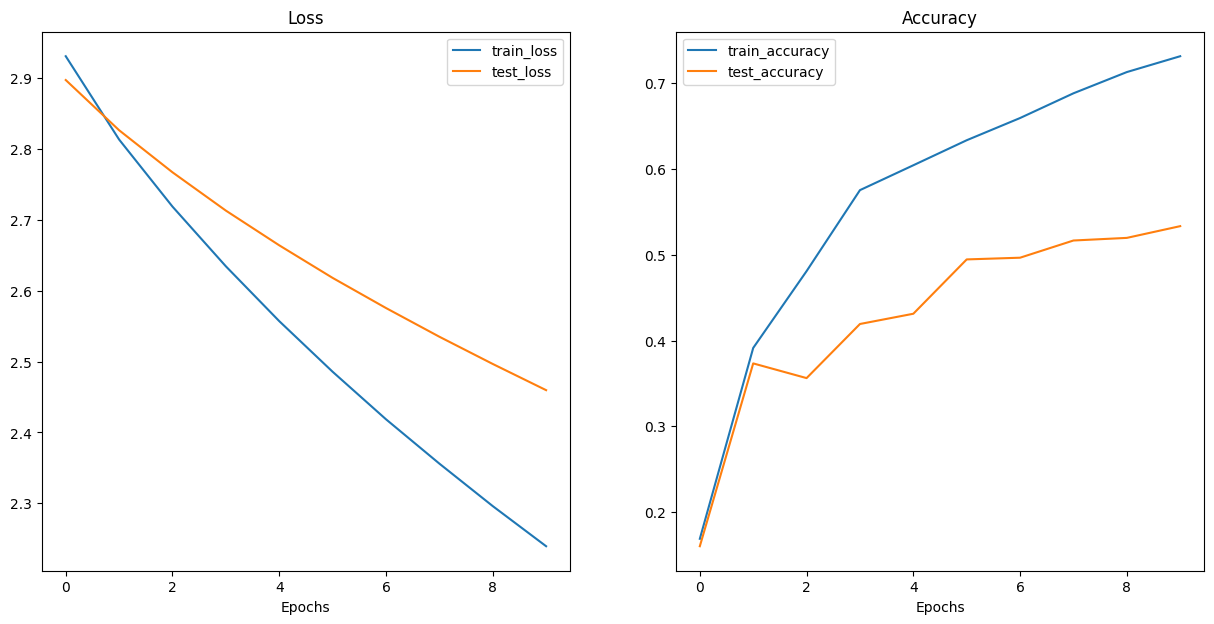

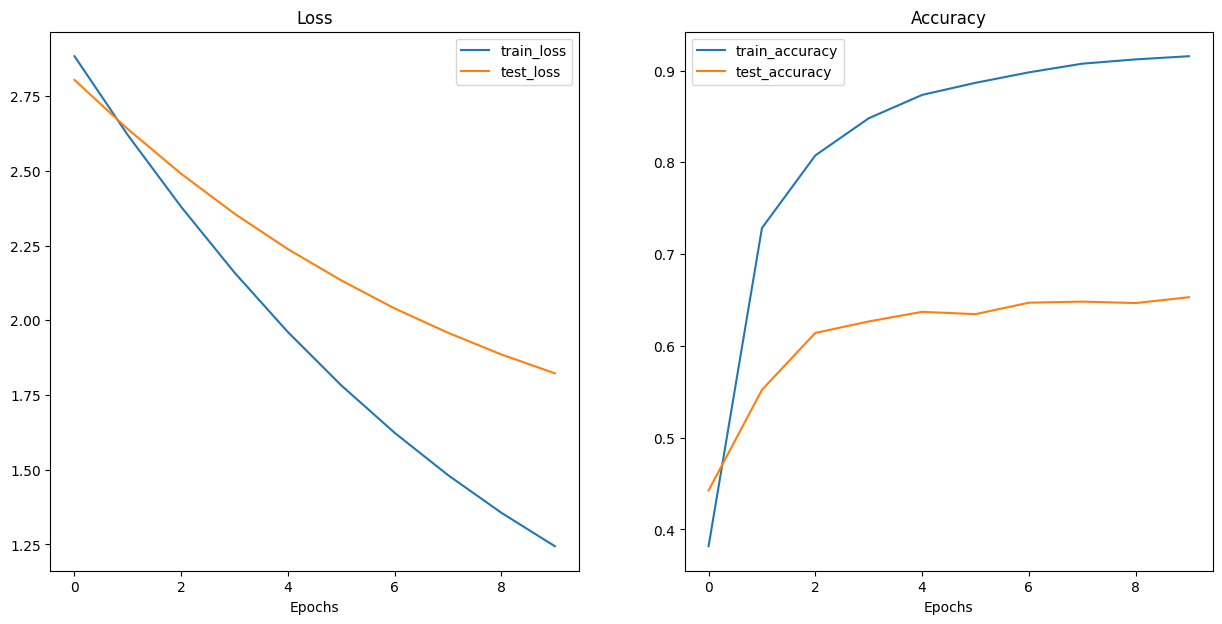

In [ ]:
for mode, data in all_results.items():
    print(f"\n=== Mode: {mode} ===")
    plot_loss_curves(data['metrics'])


Спостерігається, що модель, побудована з використанням TF-IDF-векторизації, демонструє найкращі результати за показниками точності та значеннями функції втрат. Крім того, аналіз кривих втрат і точності за епохами показує менший розрив між результатами на навчальній та валідаційній вибірках. Це свідчить про стабільне навчання моделі, відсутність вираженого перенавчання та здатність узагальнювати дані, що підтверджується  якістю на тестовій вибірці. Проте, можливим є також недонавчання, тому модель потребує покращення та ускладнення орхітектрури додатковими шарами

Bисновки:
Завантажуємо мережу з найкращим показником === Mode: TF-IDF ===

In [ ]:
# Saving model
model_best = all_results['TF-IDF']['model']
torch.save(model_best.state_dict(), "best_model.pth")
print("Модель збережена!")

# Download the model
loaded_model_best = LogisticRegressionModel (input_dim, output_dim) #

loaded_model_best.load_state_dict(torch.load("best_model.pth"))
loaded_model_best.eval()
print("Модель успішно завантажена!")

Модель збережена!
Модель успішно завантажена!


У випадках, коли є можливість використати готову бібліотеку, нам варто надавати перевагу саме їй, оскільки такі інструменти зазвичай уже оптимізовані та налаштовані для досягнення високої ефективності. Тому доцільно застосовувати вбудовані методи векторизації тексту. Вони автоматично токенізують текст, формують словник відповідно до заданого шаблону,  можуть враховувати стоп-слова та інші параметри обробки. Крім того, такі функції повертають результат у вигляді розрідженої матриці, що дозволяє раціонально використовувати пам’ять.
Тому ми будемо застосовувати CountVectorizer, TfidfVectorizer для створення різних режимів векторизації. Тим самим ми покращимо наведені ручні методи токенізації або побудови словника, що виступає одним із пунктів завдання до практикуму


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Dictionary for storing matrices and dataloaders for each mode
datasets = {}

# Vectorizer parameters
vectorizer_params = {
    "token_pattern": r'\b[a-zA-Z0-9]{4,}\b',
    "max_df": 0.8,
    "min_df": 5,
    "max_features": 20000
}

for mode in ['bin', 'TF', 'IDF', 'TF-IDF']:
    print(f"\n=== Mode: {mode} ===")

    if mode == 'bin':
        vectorizer = CountVectorizer(binary=True, **vectorizer_params)
    else:  # Для TF, IDF, TF-IDF використаємо TfidfVectorizer
        use_idf = mode in ['IDF', 'TF-IDF']
        norm = 'l2' if mode in ['TF-IDF'] else None  # Для TF-IDF нормалізація
        vectorizer = TfidfVectorizer(
            use_idf=use_idf,
            norm=norm,
            sublinear_tf=(mode=='TF'),
            **vectorizer_params
        )

    feature_matrix_train = vectorizer.fit_transform(newsgroups_train.data)
    feature_matrix_test = vectorizer.transform(newsgroups_test.data)

    print("Train shape:", feature_matrix_train.shape[1])
    print("Test shape: ", feature_matrix_test.shape[1])

    # Preparing the dataset and dataloader
    train_data, train_loader = prepare_data(feature_matrix_train, newsgroups_train.target)
    test_data, test_loader   = prepare_data(feature_matrix_test, newsgroups_test.target)


    datasets[mode] = {
        'train_loader': train_loader,
        'test_loader': test_loader
    }




=== Mode: bin ===
Train shape: 14842
Test shape:  14842

=== Mode: TF ===
Train shape: 14842
Test shape:  14842

=== Mode: IDF ===
Train shape: 14842
Test shape:  14842

=== Mode: TF-IDF ===
Train shape: 14842
Test shape:  14842


Перевіряємо розмірність лодерів. Бачимо, що ознак є на 1 менше. Це  повязано з тим, що вбудовані методи зазвичай не додають окремий токен <UNK> з індексом 0 для невідомих слів. Вони просто ігнорують слова, яких немає у словнику, під час перетворення тексту у вектор.


In [ ]:
input_dim = feature_matrix_train.shape[1]
output_dim = len(set(newsgroups_train.target))
input_dim, output_dim

(14842, 20)

Реалізуємо навчання та тестування моделей для заданиз режимів

In [ ]:
torch.manual_seed(seed=42)
all_results = {}
for mode in modes:
    print(f"\n=== Mode: {mode} ===")

    train_loader = datasets[mode]['train_loader']
    test_loader = datasets[mode]['test_loader']

    model = LogisticRegressionModel(input_dim, output_dim)
    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    metrics = train(
        model,
        train_loader,
        test_loader,
        optimizer,
        loss_fn,
        accuracy_fn,
        epochs=10,
        device=device)

    all_results[mode] = {
        "model": model,
        "metrics": metrics}


=== Mode: bin ===


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.5069 | train_acc: 0.6008 | test_loss: 1.3844 | test_acc: 0.6267
Epoch: 2 | train_loss: 0.5009 | train_acc: 0.8941 | test_loss: 1.3836 | test_acc: 0.6281
Epoch: 3 | train_loss: 0.3312 | train_acc: 0.9410 | test_loss: 1.4137 | test_acc: 0.6260
Epoch: 4 | train_loss: 0.2557 | train_acc: 0.9549 | test_loss: 1.4634 | test_acc: 0.6200
Epoch: 5 | train_loss: 0.2100 | train_acc: 0.9610 | test_loss: 1.5115 | test_acc: 0.6138
Epoch: 6 | train_loss: 0.1849 | train_acc: 0.9647 | test_loss: 1.5625 | test_acc: 0.6085
Epoch: 7 | train_loss: 0.1628 | train_acc: 0.9669 | test_loss: 1.6131 | test_acc: 0.6009
Epoch: 8 | train_loss: 0.1489 | train_acc: 0.9685 | test_loss: 1.6687 | test_acc: 0.5976
Epoch: 9 | train_loss: 0.1365 | train_acc: 0.9689 | test_loss: 1.7190 | test_acc: 0.5947
Epoch: 10 | train_loss: 0.1315 | train_acc: 0.9691 | test_loss: 1.7800 | test_acc: 0.5886

=== Mode: TF ===


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.5075 | train_acc: 0.5974 | test_loss: 1.4697 | test_acc: 0.6155
Epoch: 2 | train_loss: 0.5023 | train_acc: 0.8929 | test_loss: 1.4510 | test_acc: 0.6210
Epoch: 3 | train_loss: 0.3388 | train_acc: 0.9393 | test_loss: 1.4788 | test_acc: 0.6264
Epoch: 4 | train_loss: 0.2646 | train_acc: 0.9532 | test_loss: 1.5436 | test_acc: 0.6190
Epoch: 5 | train_loss: 0.2164 | train_acc: 0.9610 | test_loss: 1.5959 | test_acc: 0.6152
Epoch: 6 | train_loss: 0.1872 | train_acc: 0.9635 | test_loss: 1.6502 | test_acc: 0.6094
Epoch: 7 | train_loss: 0.1667 | train_acc: 0.9659 | test_loss: 1.7133 | test_acc: 0.6070
Epoch: 8 | train_loss: 0.1511 | train_acc: 0.9681 | test_loss: 1.7561 | test_acc: 0.6045
Epoch: 9 | train_loss: 0.1418 | train_acc: 0.9688 | test_loss: 1.8232 | test_acc: 0.5953
Epoch: 10 | train_loss: 0.1331 | train_acc: 0.9697 | test_loss: 1.8924 | test_acc: 0.5896

=== Mode: IDF ===


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 2.4776 | train_acc: 0.5888 | test_loss: 3.8024 | test_acc: 0.5773
Epoch: 2 | train_loss: 0.4319 | train_acc: 0.9007 | test_loss: 4.8143 | test_acc: 0.5539
Epoch: 3 | train_loss: 0.2767 | train_acc: 0.9473 | test_loss: 4.1056 | test_acc: 0.5680
Epoch: 4 | train_loss: 0.1757 | train_acc: 0.9625 | test_loss: 4.1394 | test_acc: 0.5724
Epoch: 5 | train_loss: 0.1921 | train_acc: 0.9670 | test_loss: 4.3941 | test_acc: 0.5652
Epoch: 6 | train_loss: 0.1479 | train_acc: 0.9684 | test_loss: 4.2936 | test_acc: 0.5722
Epoch: 7 | train_loss: 0.1410 | train_acc: 0.9698 | test_loss: 4.3605 | test_acc: 0.5714
Epoch: 8 | train_loss: 0.1188 | train_acc: 0.9703 | test_loss: 4.3908 | test_acc: 0.5708
Epoch: 9 | train_loss: 0.1478 | train_acc: 0.9697 | test_loss: 4.4310 | test_acc: 0.5694
Epoch: 10 | train_loss: 0.1355 | train_acc: 0.9709 | test_loss: 4.4847 | test_acc: 0.5673

=== Mode: TF-IDF ===


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 2.1254 | train_acc: 0.6044 | test_loss: 1.7065 | test_acc: 0.6431
Epoch: 2 | train_loss: 1.0112 | train_acc: 0.8740 | test_loss: 1.4104 | test_acc: 0.6636
Epoch: 3 | train_loss: 0.6501 | train_acc: 0.9188 | test_loss: 1.3041 | test_acc: 0.6649
Epoch: 4 | train_loss: 0.4703 | train_acc: 0.9403 | test_loss: 1.2531 | test_acc: 0.6636
Epoch: 5 | train_loss: 0.3653 | train_acc: 0.9526 | test_loss: 1.2311 | test_acc: 0.6601
Epoch: 6 | train_loss: 0.2964 | train_acc: 0.9605 | test_loss: 1.2196 | test_acc: 0.6563
Epoch: 7 | train_loss: 0.2492 | train_acc: 0.9646 | test_loss: 1.2154 | test_acc: 0.6536
Epoch: 8 | train_loss: 0.2151 | train_acc: 0.9666 | test_loss: 1.2177 | test_acc: 0.6518
Epoch: 9 | train_loss: 0.1898 | train_acc: 0.9687 | test_loss: 1.2193 | test_acc: 0.6504
Epoch: 10 | train_loss: 0.1706 | train_acc: 0.9695 | test_loss: 1.2289 | test_acc: 0.6475



=== Mode: bin ===

=== Mode: TF ===

=== Mode: IDF ===

=== Mode: TF-IDF ===


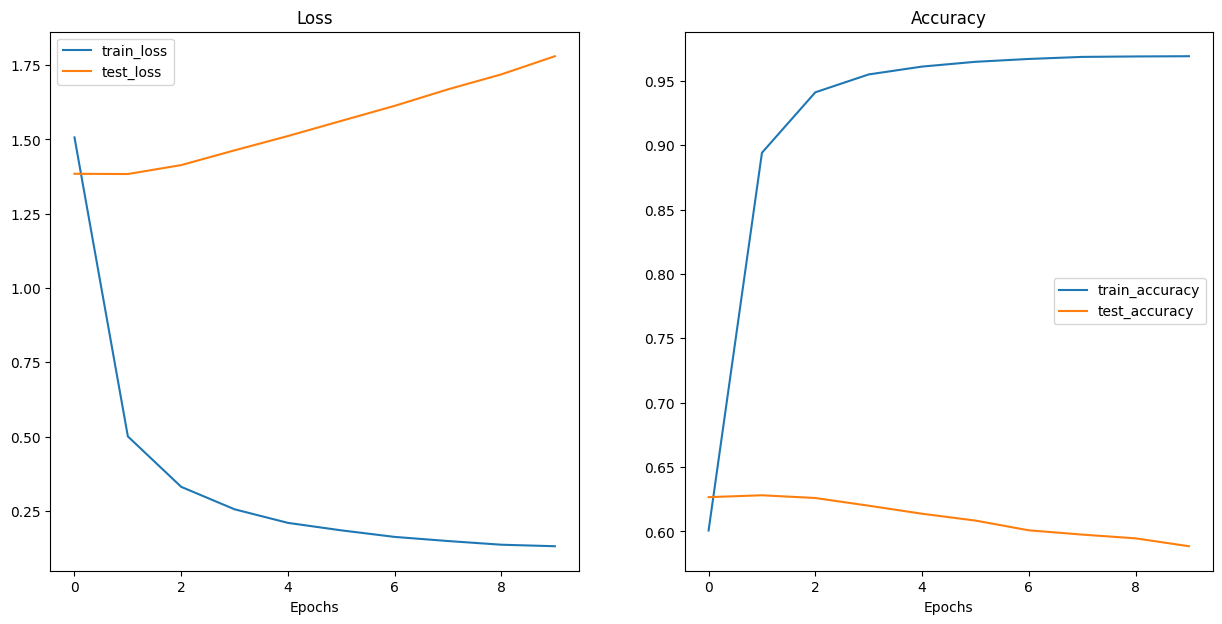

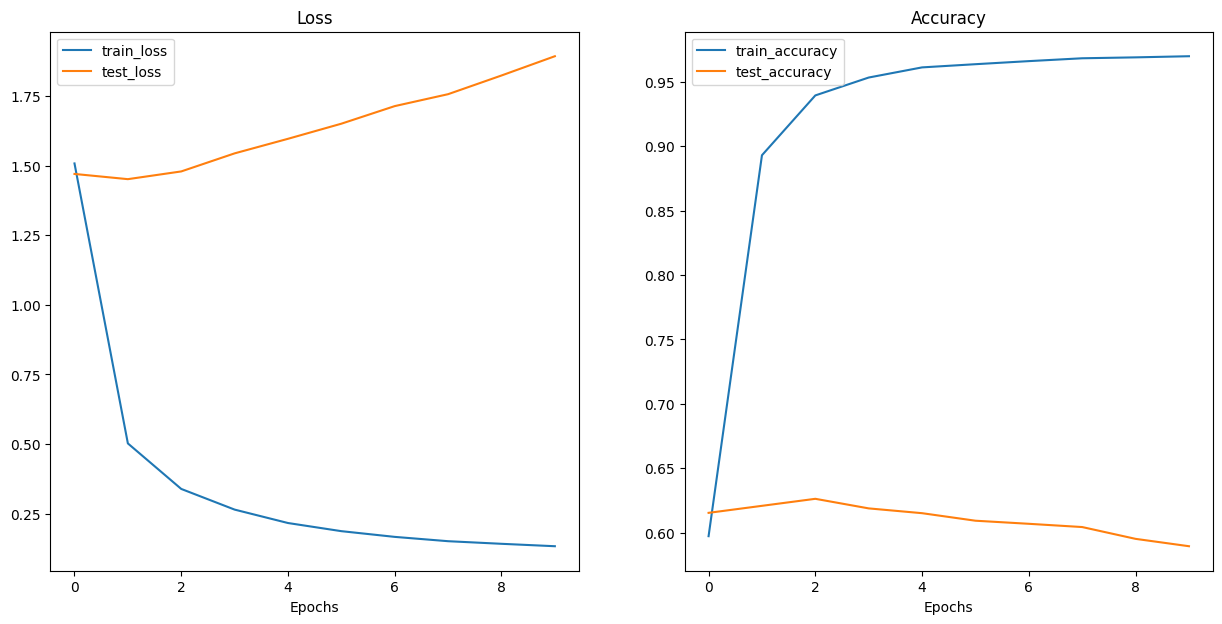

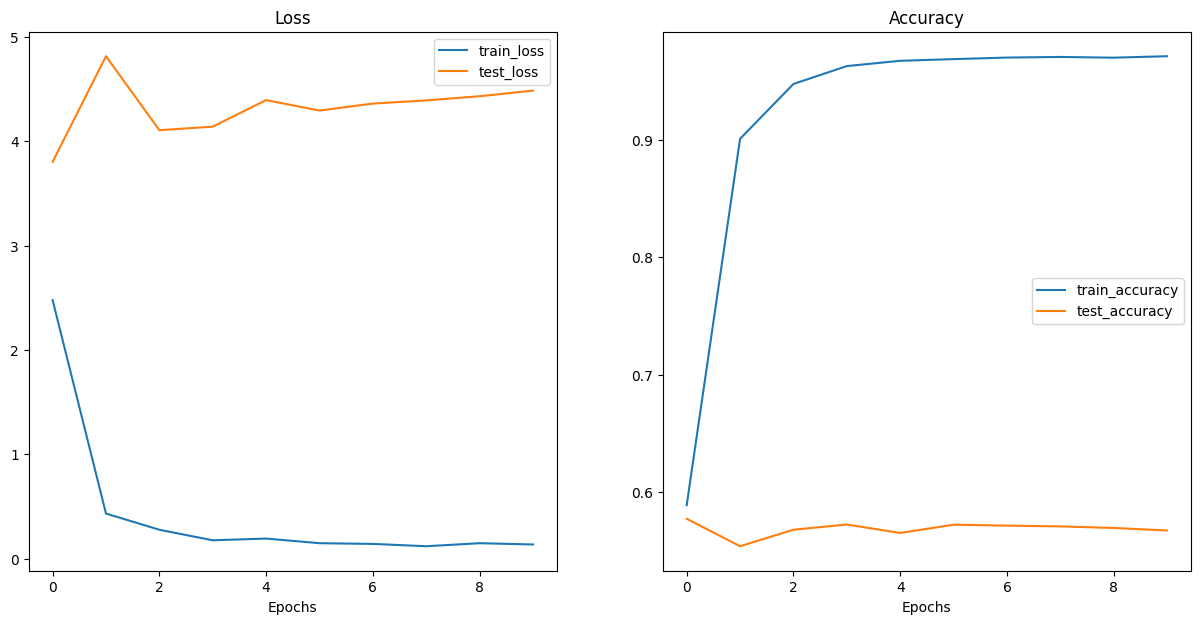

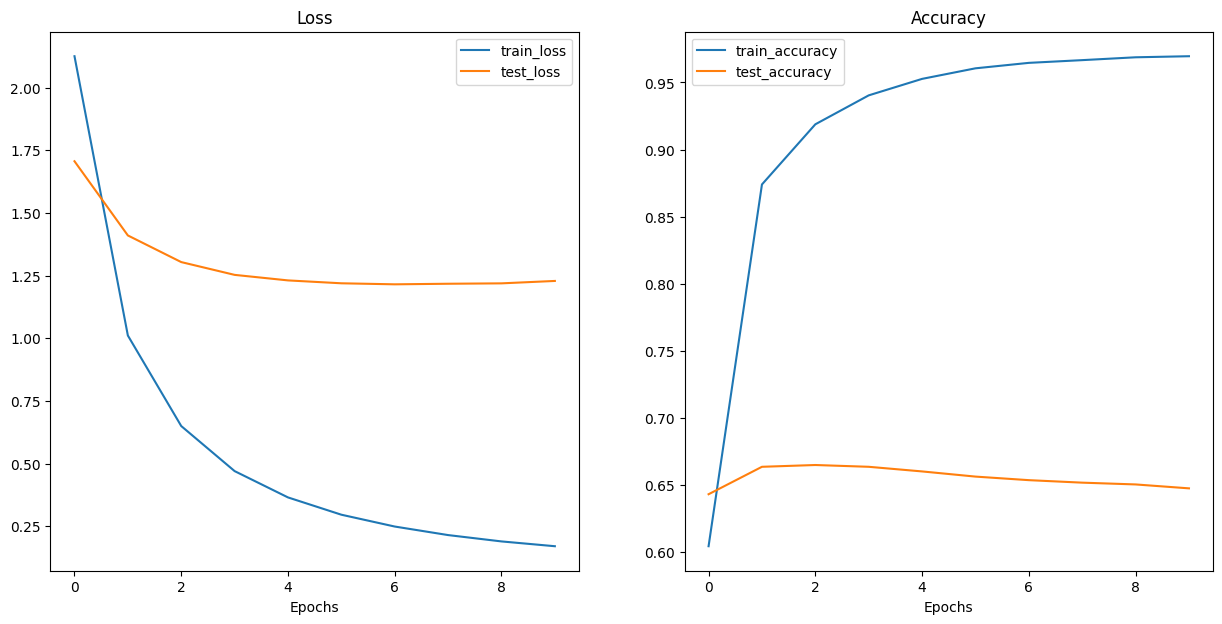

In [ ]:
for mode, data in all_results.items():
    print(f"\n=== Mode: {mode} ===")
    plot_loss_curves(data['metrics'])


Спостерігається, що модель, побудована з використанням TF-IDF-векторизації, демонструє кращі результати за показниками точності та значеннями функції втрат порівняно з моделлю на основі ручного векторизатора. Навчальна точність швидко зростає до приблизно 0.97
Водночас, значення функції втрат є меншими, порівняно із підходом, реалізованим вручну.

Після 3–4 епох тестова точність починає поступово знижуватися, незважаючи на подальше зростання точності на тренувальній вибірці. Така динаміка є ознакою перенавчання.

Тобто, модель із використанням вбудованих методів векторизації навчається швидше, ніж модель із ручною токенізацією та побудовою словника. Це пояснюється якіснішою обробкою тексту, автоматичною нормалізацією та оптимізацією ознак. Водночас швидша збіжність супроводжується вищим ризиком перенавчання.

Аналіз кривих втрат і точності за епохами показує наявність розриву між результатами на навчальній і валідаційній вибірках. Хоча на початкових етапах цей розрив є відносно контрольованим, з подальшим навчанням він збільшується. Порівняно з ручними методами векторизації, цей розрив є більш вираженим, що додатково підтверджує схильність моделі з TF-IDF до швидшого перенавчання.

На мою думку, основними причинами перенавчання та дещо гірших результатів на тестовій вибірці при використанні вбудованого TF-IDF порівняно з ручним підходом є наступні фактори.

По-перше, L2-нормалізація у вбудованому TF-IDF стабілізує градієнти та прискорює навчання, завдяки чому модель швидко досягає високої точності на тренувальних даних. По-друге, використання sublinear_tf і згладжування IDF виділяє більш інформативні ознаки, що також сприяє швидшому запам’ятовуванню тренувальної вибірки, проте підвищує ризик перенавчання.

У ручному підході наявність спеціального токена <UNK>, який збирає всі невідомі слова в один категорійний елемент, трохи знижує ризик перенавчання, адже модель менше підлаштовується під рідкісні або невідомі слова.

Bисновки:
Завантажуємо модель з найкращим показником === Mode: TF-IDF ===

In [ ]:
# Збереження моделі
model_best = all_results['TF-IDF']['model']
torch.save(model_best.state_dict(), "best_model.pth")
print("Модель збережена!")

# Завантаження моделі
loaded_model_best = LogisticRegressionModel (input_dim, output_dim) #

loaded_model_best.load_state_dict(torch.load("best_model.pth"))
loaded_model_best.eval()
print("Модель успішно завантажена!")

Модель збережена!
Модель успішно завантажена!
